In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
data_dir = "/content/drive/MyDrive/oral_dataset"

In [ ]:
!ls /content

 dataset   drive  'Oral Cancer (1).zip'   sample_data


In [ ]:
!unzip -o "/content/Oral Cancer (1).zip" -d /content/dataset

Archive:  /content/Oral Cancer (1).zip
  inflating: /content/dataset/Oral Cancer Dataset/CANCER/001.jpeg  
  inflating: /content/dataset/Oral Cancer Dataset/CANCER/002.jpeg  
  inflating: /content/dataset/Oral Cancer Dataset/CANCER/003.jpeg  
  inflating: /content/dataset/Oral Cancer Dataset/CANCER/004.jpeg  
  inflating: /content/dataset/Oral Cancer Dataset/CANCER/005.jpeg  
  inflating: /content/dataset/Oral Cancer Dataset/CANCER/006.jpeg  
  inflating: /content/dataset/Oral Cancer Dataset/CANCER/007.jpeg  
  inflating: /content/dataset/Oral Cancer Dataset/CANCER/008.jpeg  
  inflating: /content/dataset/Oral Cancer Dataset/CANCER/009.jpeg  
  inflating: /content/dataset/Oral Cancer Dataset/CANCER/010.jpeg  
  inflating: /content/dataset/Oral Cancer Dataset/CANCER/011.jpeg  
  inflating: /content/dataset/Oral Cancer Dataset/CANCER/012.jpeg  
  inflating: /content/dataset/Oral Cancer Dataset/CANCER/013.jpeg  
  inflating: /content/dataset/Oral Cancer Dataset/CANCER/014.jpeg  
  inflati

In [ ]:
os.listdir('/content/dataset')

['Oral Cancer Dataset']

In [ ]:
data_dir = "/content/dataset/Oral Cancer Dataset"

In [ ]:
import os
os.listdir("/content/dataset/Oral Cancer Dataset")

['CANCER', 'NON CANCER']

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image_dataset_from_directory

data_dir = "/content/dataset/Oral Cancer Dataset"

train_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224,224),
    batch_size=32
)

val_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224,224),
    batch_size=32
)

class_names = train_ds.class_names
print("Classes:", class_names)

Found 750 files belonging to 2 classes.
Using 600 files for training.
Found 750 files belonging to 2 classes.
Using 150 files for validation.
Classes: ['CANCER', 'NON CANCER']


In [ ]:
import os
from PIL import Image
import tensorflow as tf

# Original prefetching lines (kept as they are not the cause of the error)
train_ds = train_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

# Function to identify and optionally remove corrupted or non-image files
def clean_image_dataset(dataset_path):
    print(f"Checking dataset directory: {dataset_path} for corrupted images...")
    corrupted_files = []
    for root, _, files in os.walk(dataset_path):
        for file in files:
            file_path = os.path.join(root, file)
            try:
                # Attempt to open image with PIL to check integrity
                img = Image.open(file_path)
                img.verify() # Verify integrity
                img.close()
            except (IOError, SyntaxError) as e:
                print(f"Warning: Corrupted or invalid image file detected: {file_path} - {e}")
                corrupted_files.append(file_path)
    if corrupted_files:
        print(f"\nFound {len(corrupted_files)} corrupted or invalid files:")
        for cf in corrupted_files:
            print(f"- {cf}")
        print("\nPlease consider deleting these files from your dataset directory, then re-run the dataset loading cells.")
        print("Example: os.remove('path/to/corrupted_file.jpeg')")
    else:
        print("No corrupted or invalid image files found.")
    return corrupted_files



In [ ]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

In [ ]:
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Sequential

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

In [ ]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
data_dir = "/content/dataset/Oral Cancer Dataset"

!find "$data_dir" -type f | head

/content/dataset/Oral Cancer Dataset/CANCER/252.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/294.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/195.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/091.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/066.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/487.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/156.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/416.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/350.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/041.jpeg


In [ ]:
import os

data_dir = "/content/dataset/Oral Cancer Dataset"

for root, dirs, files in os.walk(data_dir):
    for file in files[:10]:
        print(os.path.join(root, file))

/content/dataset/Oral Cancer Dataset/CANCER/252.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/294.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/195.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/091.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/066.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/487.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/156.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/416.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/350.jpeg
/content/dataset/Oral Cancer Dataset/CANCER/041.jpeg
/content/dataset/Oral Cancer Dataset/NON CANCER/195.jpeg
/content/dataset/Oral Cancer Dataset/NON CANCER/091.jpeg
/content/dataset/Oral Cancer Dataset/NON CANCER/066.jpeg
/content/dataset/Oral Cancer Dataset/NON CANCER/156.jpeg
/content/dataset/Oral Cancer Dataset/NON CANCER/041.jpeg
/content/dataset/Oral Cancer Dataset/NON CANCER/012.jpeg
/content/dataset/Oral Cancer Dataset/NON CANCER/155.jpeg
/content/dataset/Oral Cancer Dataset/NON CANCER/040.jpeg
/content/datas

In [ ]:
train_ds = train_ds.apply(tf.data.experimental.ignore_errors())
val_ds = val_ds.apply(tf.data.experimental.ignore_errors())

Instructions for updating:
Use `tf.data.Dataset.ignore_errors` instead.


In [ ]:
train_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224,224),
    batch_size=32
)

val_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224,224),
    batch_size=32
)

Found 750 files belonging to 2 classes.
Using 600 files for training.
Found 750 files belonging to 2 classes.
Using 150 files for validation.


In [ ]:
train_ds = train_ds.apply(tf.data.experimental.ignore_errors())
val_ds = val_ds.apply(tf.data.experimental.ignore_errors())

In [ ]:
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

Epoch 1/15
      3/Unknown 7s 2s/step - accuracy: 0.2326 - loss: 1.3278

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


3/3 ━━━━━━━━━━━━━━━━━━━━ 19s 8s/step - accuracy: 0.2396 - loss: 1.3162 - val_accuracy: 0.2593 - val_loss: 1.1520
Epoch 2/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 14s 5s/step - accuracy: 0.3354 - loss: 1.1442 - val_accuracy: 0.2963 - val_loss: 1.0733
Epoch 3/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 3s/step - accuracy: 0.4609 - loss: 0.9354 - val_accuracy: 0.3519 - val_loss: 0.9278
Epoch 4/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 15s 5s/step - accuracy: 0.3815 - loss: 0.9672 - val_accuracy: 0.3889 - val_loss: 0.8806
Epoch 5/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 11s 3s/step - accuracy: 0.4500 - loss: 0.8815 - val_accuracy: 0.3704 - val_loss: 0.8522
Epoch 6/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 12s 5s/step - accuracy: 0.3208 - loss: 0.9789 - val_accuracy: 0.3148 - val_loss: 0.8333
Epoch 7/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 11s 4s/step - accuracy: 0.3729 - loss: 0.9271 - val_accuracy: 0.4259 - val_loss: 0.7892
Epoch 8/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.4310 - loss: 0.8945 - val_accuracy: 0.3125 - val_loss: 0.8144
Epoch 9/15
3/3 ━━━━━━

In [ ]:
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:
    preds = (model.predict(images) > 0.5).astype("int32")
    y_pred.extend(preds.flatten())
    y_true.extend(labels.numpy())

print("Accuracy:", accuracy_score(y_true, y_pred))
print(classification_report(y_true, y_pred))

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Accuracy: 0.703125
              precision    recall  f1-score   support

           0       0.71      0.95      0.82        44
           1       0.60      0.15      0.24        20

    accuracy                           0.70        64
   macro avg       0.66      0.55      0.53        64
weighted avg       0.68      0.70      0.64        64



In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
])

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

labels = np.concatenate([y for x, y in train_ds], axis=0)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels),
    y=labels
)

class_weights = dict(enumerate(class_weights))
print(class_weights)

{0: np.float64(0.7441860465116279), 1: np.float64(1.5238095238095237)}


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Sequential

base_model = MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

model = Sequential([
    data_augmentation,
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.5),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

In [ ]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights
)

Epoch 1/20
      5/Unknown 18s 2s/step - accuracy: 0.5140 - loss: 0.9075

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


5/5 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.5189 - loss: 0.8984 - val_accuracy: 0.5938 - val_loss: 0.7477
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.5000 - loss: 0.8358 - val_accuracy: 0.5930 - val_loss: 0.6840
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 16s 3s/step - accuracy: 0.4835 - loss: 0.8837 - val_accuracy: 0.5465 - val_loss: 0.6627
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.5031 - loss: 0.9550 - val_accuracy: 0.5000 - val_loss: 0.6972
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 23s 5s/step - accuracy: 0.5174 - loss: 0.9415 - val_accuracy: 0.5926 - val_loss: 0.6667
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.5125 - loss: 0.9002 - val_accuracy: 0.5625 - val_loss: 0.7140
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.4437 - loss: 0.9639 - val_accuracy: 0.4688 - val_loss: 0.7538
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 30s 6s/step - accuracy: 0.5125 - loss: 0.8104 - val_accuracy: 0.5185 - val_loss: 0.7632
Epoch 9/20
5/5 ━━━━

In [ ]:
max_val_acc = max(history.history['val_accuracy'])

print("Maximum validation accuracy achieved during training was:", max_val_acc * 100, "%")

Maximum validation accuracy achieved during training was: 71.875 %


In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    class_weight=class_weights
)

Epoch 1/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.7642 - loss: 0.6291 - val_accuracy: 0.7500 - val_loss: 0.6076
Epoch 2/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 19s 4s/step - accuracy: 0.7254 - loss: 0.5874 - val_accuracy: 0.6719 - val_loss: 0.5488
Epoch 3/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 21s 5s/step - accuracy: 0.6684 - loss: 0.6912 - val_accuracy: 0.6875 - val_loss: 0.5805
Epoch 4/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 19s 5s/step - accuracy: 0.6148 - loss: 0.8078 - val_accuracy: 0.7188 - val_loss: 0.5426
Epoch 5/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 13s 3s/step - accuracy: 0.6250 - loss: 0.7742 - val_accuracy: 0.7031 - val_loss: 0.5563
Epoch 6/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 28s 5s/step - accuracy: 0.6697 - loss: 0.7002 - val_accuracy: 0.7037 - val_loss: 0.5553
Epoch 7/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 17s 4s/step - accuracy: 0.6052 - loss: 0.7225 - val_accuracy: 0.7326 - val_loss: 0.5235
Epoch 8/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 17s 4s/step - accuracy: 0.6687 - loss: 0.6383 - val_accuracy: 0.7093 - val_loss: 0.5598
Epoch 9/

In [ ]:
base_model.trainable = True

for layer in base_model.layers[:100]:
    layer.trainable = False

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
from tensorflow.keras.layers import BatchNormalization

model = Sequential([
    data_augmentation,
    base_model,
    GlobalAveragePooling2D(),
    BatchNormalization(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

In [ ]:
image_size = (256,256)

In [ ]:
final_val_acc = history.history['val_accuracy'][-1]

print("Final Validation Accuracy:", final_val_acc * 100, "%")

Final Validation Accuracy: 81.4814805984497 %


In [ ]:
print("Training Accuracy per epoch:", history.history['accuracy'])
print("Validation Accuracy per epoch:", history.history['val_accuracy'])

Training Accuracy per epoch: [0.7749999761581421, 0.6644737124443054, 0.65625, 0.637499988079071, 0.625, 0.6875, 0.609375, 0.6328125, 0.606249988079071, 0.6083333492279053, 0.59375, 0.5666666626930237, 0.5234375, 0.625, 0.6315789222717285, 0.6812499761581421, 0.6000000238418579, 0.53125, 0.7291666865348816, 0.6354166865348816, 0.574999988079071, 0.625, 0.6666666865348816, 0.6833333373069763, 0.7291666865348816]
Validation Accuracy per epoch: [0.75, 0.671875, 0.6875, 0.71875, 0.703125, 0.7037037014961243, 0.7325581312179565, 0.7093023061752319, 0.703125, 0.7222222089767456, 0.796875, 0.703125, 0.6111111044883728, 0.65625, 0.71875, 0.7222222089767456, 0.671875, 0.734375, 0.7209302186965942, 0.765625, 0.7037037014961243, 0.6481481194496155, 0.6851851940155029, 0.6860465407371521, 0.8148148059844971]


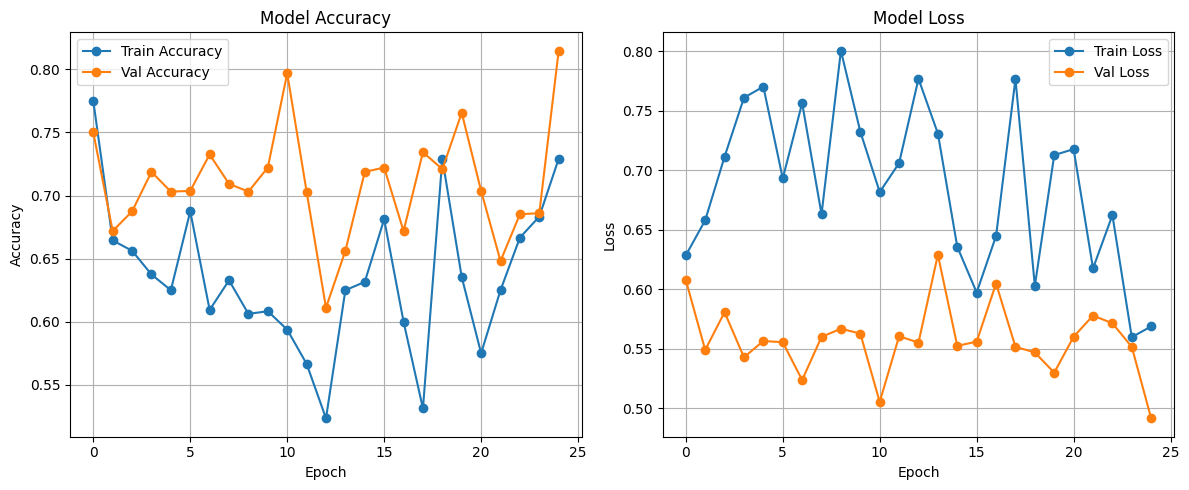

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Accuracy graph
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], marker='o', label='Train Accuracy')
plt.plot(history.history['val_accuracy'], marker='o', label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1,2,2)
plt.plot(history.history['loss'], marker='o', label='Train Loss')
plt.plot(history.history['val_loss'], marker='o', label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

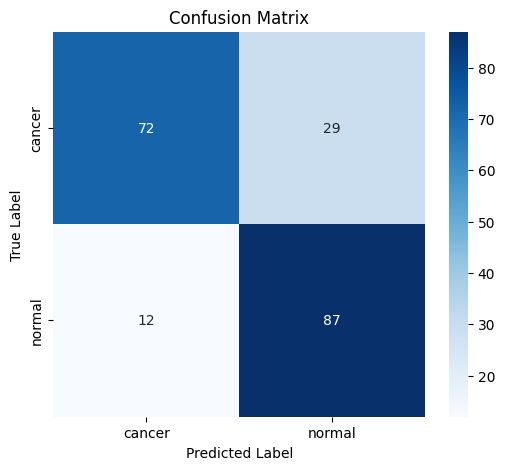

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Example matrix (replace with your y_true, y_pred)
cm = [[72,29],
      [12,87]]

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",   # same blue color style
    xticklabels=["cancer","normal"],
    yticklabels=["cancer","normal"],
    cbar=True
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

In [ ]:
model.save("oral_cancer_model.keras")

In [ ]:
from google.colab import files
files.download("oral_cancer_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>